# Which events change how stocks move together, and do the changes last?

**DSAI4102 Applied Data Mining · Notebook 3 of 3** (run after `stocks.ipynb` and `comovement_rules.ipynb`)
Farid Abdul Rehman · Muzayyan Parkar · Mohamad Zain

`comovement_rules.ipynb` showed that, once the market is removed, the S&P 100 has a real co-movement structure
(Q0). This notebook asks what happens to that structure when news arrives. Three questions, each written down with
the result that would answer "no" before anything was run:

| Question | What it means here | Answer "no" if |
|---|---|---|
| **Q1. Do events explain the strangest days?** | The 1% most unusual trading days (27 days, picked by an Isolation Forest that never sees any news). Do more of them fall on an event than a randomly shifted calendar would give? | the real calendar matches no more unusual days than shifted calendars |
| **Q2. Who reacts to scheduled news and to company news?** | Which *sectors* make more major moves than usual on Fed decision, inflation (CPI) and jobs-report days; and when a company reports earnings, whether stocks in its sector follow | every sector's move rate on event days is within its bootstrap interval of quiet days; earnings moves pull peers no more than ordinary moves |
| **Q3. When events change co-movement, does the change last?** | First, do one-off shocks land on *structure breaks* (weeks when who-moves-with-whom changes)? Second, after each shock, does the structure return to normal within about a year? | shocks sit at ordinary break scores; and changes that start after a shock fade back to normal drift |

**Inputs:** `data/prices.csv`, `data/stocks.csv` (from `stocks.ipynb`), `outputs/rules/top_anomalous_days.csv`
(from `comovement_rules.ipynb`, used as a check). **Builds:** `data/events.csv` and `data/earnings_dates.csv`
(Section 2; the earnings download needs internet access to Yahoo Finance). **Outputs:** every table and figure in
`outputs/events/`, every quoted number in `outputs/events/key_numbers_events.json`.

## 1. Settings

The first block repeats `comovement_rules.ipynb`'s settings, so the items and unusual days are identical. The second
block holds the settings new to this notebook.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from mlxtend.frequent_patterns import fpgrowth
from scipy.stats import hypergeom, mannwhitneyu
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- same as comovement_rules.ipynb -----------------------------------------------
MARKET = "SPY"
STUDY_START = "2016-01-01"
BETA_WINDOW = 252
VOL_WINDOW = 60
Z_K = 1.0
SEED = 42
stocks = pd.read_csv("data/stocks.csv")
TICKERS = stocks["ticker"].tolist()
GROUP_OF = dict(zip(stocks["ticker"], stocks["sector"]))          # "group" = GICS sector
SECTORS = stocks["sector"].value_counts().index.tolist()
SEMIS = stocks.loc[stocks["semiconductor"], "ticker"].tolist()

# ---- new in this notebook ---------------------------------------------------------
DATA = Path("data")
EVENTS_PATH = DATA / "events.csv"
EARNINGS_PATH = DATA / "earnings_dates.csv"
OUT_DIR = Path("outputs/events")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TOP_SHARE = 0.01          # "unusual day" = top 1% of Isolation Forest scores (as in comovement_rules.ipynb)
SHOCK_TOLERANCE = 1       # a one-off shock matches an unusual day within +-1 trading day
N_SHIFTS = 1000           # random calendar shifts for the event-date test
MIN_SHIFT = 21            # a shift moves the calendar by at least one month
SPAN = 126                # half-year windows before and after a date for structure comparisons
GRID_STEP = 5             # local break score every 5 trading days (weekly)
PEAK_GAP = 63             # break peaks must be at least a quarter apart
NEAR = 21                 # events within +-21 trading days of a break peak are listed as "nearby"
H2_OFFSETS = list(range(0, 505, 21))   # recovery curve: post-event windows start 0..504 trading days after the event
EVENT_TYPES = ["FOMC", "CPI", "NFP", "SHOCK"]
COND_MIN_SUPPORT = 0.25   # event rules: consequent on at least 25% of the event days ...
COND_MIN_COUNT = 5        # ... and on at least 5 event days
COND_MIN_LIFT = 1.5
FDR_Q = 0.05
STRESS_Q = 0.95           # "market stress" day: SPY's trailing 21-day volatility in its top 5% (only describes unusual days)
rng = np.random.default_rng(SEED)
KEY = {}
print(f"{len(TICKERS)} stocks in {len(SECTORS)} sectors; semiconductor stocks: {SEMIS}")

100 stocks in 11 sectors; semiconductor stocks: ['AMAT', 'AMD', 'AVGO', 'INTC', 'LRCX', 'MU', 'NVDA', 'QCOM', 'TXN']


In [2]:
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SECTOR_COLORS = dict(zip(SECTORS, ["#2a78d6", "#eb6834", "#1baf7a", "#7a4fc9", "#b3261e", "#d4a106",
                                   "#0f8b8d", "#898781", "#c2569b", "#5b8c2a", "#3b3b3b"]))
SHORT = {"Information Technology": "Tech", "Communication Services": "Comms", "Consumer Discretionary": "Cons. disc.",
         "Consumer Staples": "Staples", "Health Care": "Health", "Financials": "Financials", "Industrials": "Industrials",
         "Energy": "Energy", "Utilities": "Utilities", "Real Estate": "Real est.", "Materials": "Materials",
         "Semiconductors": "Semis"}
TYPE_COLORS = {"FOMC": "#7a4fc9", "CPI": "#eb6834", "NFP": "#1baf7a", "SHOCK": "#b3261e", "EARN": "#2a78d6"}
HIGHLIGHT = "#b3261e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")


def year_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def short_label(name, width=24):
    # Cut a long event name at a word boundary for figure labels.
    name = name.split(" (")[0].split(";")[0]
    if len(name) <= width:
        return name
    return name[:width].rsplit(" ", 1)[0] + "..."


def benjamini_hochberg(p_values, q=FDR_Q, n_tests=None):
    # True for every p-value that survives the Benjamini-Hochberg procedure (same function as comovement_rules.ipynb).
    p = np.asarray(p_values, dtype=float)
    m = len(p) if n_tests is None else n_tests
    order = np.argsort(p)
    passed = p[order] <= q * np.arange(1, len(p) + 1) / m
    keep = np.zeros(len(p), dtype=bool)
    if passed.any():
        keep[order[:np.max(np.nonzero(passed)[0]) + 1]] = True
    return keep

## 2. The events we test, and why

Events disrupt the market: news about interest rates, inflation, the economy, a company or a crisis changes what
investors expect, and can change which stocks move together. We test four kinds of dated news.

| Kind | Count | Why it is in the test | Fair test? |
|---|---|---|---|
| **FOMC rate decisions** (Federal Reserve) | 8 a year, plus 2 emergency cuts in March 2020 | Interest rates set the value of future profits and the margins of banks; stock returns are on average higher on these days (Savor & Wilson, 2013; Lucca & Moench, 2015), and a surprise rate cut lifts stocks (Bernanke & Kuttner, 2005) | **Yes**: dates fixed months in advance |
| **CPI releases** (inflation) | monthly | Inflation drives expected rate changes | **Yes** |
| **Jobs reports** (non-farm payrolls, NFP) | monthly | The other half of the Fed's mandate; moves rate expectations | **Yes** |
| **One-off shocks** | 19 | Elections, the COVID crash, tariffs, a war, a bank failure, five AI events (ChatGPT, GPT-4, Nvidia's guidance, DeepSeek, Oracle's backlog) | **No**: picked by hand *because* markets moved, so they are always reported separately |
| **Company earnings** | about 4 a year per company | Company news that may carry information about its whole sector (Foster, 1981) | **Yes** for dates; added as company-level news |

**Reaction day.** Every event is placed on the first trading day the market could react: FOMC decisions come at
2 p.m. and CPI and jobs reports at 8:30 a.m., so the same day; a weekend announcement counts on Monday; an earnings
report at or after the 4 p.m. close counts the next trading day.

**Where the dates come from.** FOMC: the Federal Reserve's meeting calendars. CPI and jobs reports: the Bureau of
Labor Statistics release archives (including the 2025 government shutdown: no October 2025 reports, and delayed
releases in October-December 2025). Shocks: each row links a news report or official release confirming the date.
Earnings: Yahoo Finance via `yfinance`.

References: Savor & Wilson (2013), *J. Financial and Quantitative Analysis* 48(2), doi:10.1017/S002210901300015X;
Lucca & Moench (2015), *J. Finance* 70(1), doi:10.1111/jofi.12196; Bernanke & Kuttner (2005), *J. Finance* 60(3),
doi:10.1111/j.1540-6261.2005.00760.x; Foster (1981), *J. Accounting and Economics* 3(3), doi:10.1016/0165-4101(81)90003-3.

**2.1 Fed rate decisions.** The decision day is the second day of each two-day meeting.

In [3]:
FOMC_SOURCE_RECENT = "https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm"
FOMC_SOURCE_OLD = "https://www.federalreserve.gov/monetarypolicy/fomchistorical{year}.htm"
FOMC = {
    2016: ["01-27", "03-16", "04-27", "06-15", "07-27", "09-21", "11-02", "12-14"],
    2017: ["02-01", "03-15", "05-03", "06-14", "07-26", "09-20", "11-01", "12-13"],
    2018: ["01-31", "03-21", "05-02", "06-13", "08-01", "09-26", "11-08", "12-19"],
    2019: ["01-30", "03-20", "05-01", "06-19", "07-31", "09-18", "10-30", "12-11"],
    # 2020: 3 Mar emergency cut (statement 3 Mar); Sunday 15 Mar emergency cut; 17-18 Mar meeting cancelled.
    2020: ["01-29", "03-03", "03-15", "04-29", "06-10", "07-29", "09-16", "11-05", "12-16"],
    2021: ["01-27", "03-17", "04-28", "06-16", "07-28", "09-22", "11-03", "12-15"],
    2022: ["01-26", "03-16", "05-04", "06-15", "07-27", "09-21", "11-02", "12-14"],
    2023: ["02-01", "03-22", "05-03", "06-14", "07-26", "09-20", "11-01", "12-13"],
    2024: ["01-31", "03-20", "05-01", "06-12", "07-31", "09-18", "11-07", "12-18"],
    2025: ["01-29", "03-19", "05-07", "06-18", "07-30", "09-17", "10-29", "12-10"],
    2026: ["01-28", "03-18", "04-29", "06-17", "07-29", "09-16", "10-28", "12-09"],
}
FOMC_NOTES = {"2020-03-03": "emergency cut (unscheduled)", "2020-03-15": "emergency cut on a Sunday (unscheduled)"}

**2.2 CPI and jobs-report release dates**, read from the file names in the BLS archives.

In [4]:
# ---------------------------------------------------------------------------------------------
# CPI release dates, read from the file names in the BLS archive (cpi_MMDDYYYY.htm).
# Note the 2025 government shutdown: September CPI came out on 24 Oct 2025, October CPI was never
# published, and November CPI came out on 18 Dec 2025.
# ---------------------------------------------------------------------------------------------
CPI_SOURCE = "https://www.bls.gov/bls/news-release/cpi.htm"
CPI = """
01202016 02192016 03162016 04142016 05172016 06162016 07152016 08162016 09162016 10182016 11172016 12152016
01182017 02152017 03152017 04142017 05122017 06142017 07142017 08112017 09142017 10132017 11152017 12132017
01122018 02142018 03132018 04112018 05102018 06122018 07122018 08102018 09132018 10112018 11142018 12122018
01112019 02132019 03122019 04102019 05102019 06122019 07112019 08132019 09122019 10102019 11132019 12112019
01142020 02132020 03112020 04102020 05122020 06102020 07142020 08122020 09112020 10132020 11122020 12102020
01132021 02102021 03102021 04132021 05122021 06102021 07132021 08112021 09142021 10132021 11102021 12102021
01122022 02102022 03102022 04122022 05112022 06102022 07132022 08102022 09132022 10132022 11102022 12132022
01122023 02142023 03142023 04122023 05102023 06132023 07122023 08102023 09132023 10122023 11142023 12122023
01112024 02132024 03122024 04102024 05152024 06122024 07112024 08142024 09112024 10102024 11132024 12112024
01152025 02122025 03122025 04102025 05132025 06112025 07152025 08122025 09112025 10242025 12182025
01132026 02132026 03112026 04102026 05122026 06102026 07142026 08122026 09112026 10142026 11102026
""".split()

# ---------------------------------------------------------------------------------------------
# Employment Situation (jobs report, NFP) release dates from the BLS archive (empsit_MMDDYYYY.htm).
# 2025 shutdown: no October 2025 release; September data came out 20 Nov, November data 16 Dec 2025.
# ---------------------------------------------------------------------------------------------
NFP_SOURCE = "https://www.bls.gov/bls/news-release/empsit.htm"
NFP = """
01082016 02052016 03042016 04012016 05062016 06032016 07082016 08052016 09022016 10072016 11042016 12022016
01062017 02032017 03102017 04072017 05052017 06022017 07072017 08042017 09012017 10062017 11032017 12082017
01052018 02022018 03092018 04062018 05042018 06012018 07062018 08032018 09072018 10052018 11022018 12072018
01042019 02012019 03082019 04052019 05032019 06072019 07052019 08022019 09062019 10042019 11012019 12062019
01102020 02072020 03062020 04032020 05082020 06052020 07022020 08072020 09042020 10022020 11062020 12042020
01082021 02052021 03052021 04022021 05072021 06042021 07022021 08062021 09032021 10082021 11052021 12032021
01072022 02042022 03042022 04012022 05062022 06032022 07082022 08052022 09022022 10072022 11042022 12022022
01062023 02032023 03102023 04072023 05052023 06022023 07072023 08042023 09012023 10062023 11032023 12082023
01052024 02022024 03082024 04052024 05032024 06072024 07052024 08022024 09062024 10042024 11012024 12062024
01102025 02072025 03072025 04042025 05022025 06062025 07032025 08012025 09052025 11202025 12162025
01092026 02112026 03062026 04032026 05082026 06052026 07022026 08072026 09042026 10022026 11062026
""".split()

**2.3 One-off shocks.** Hand-picked big market stories, each with a source that confirms the date. This list is
a biased sample (chosen because the market moved), so it is always reported separately from the scheduled events.

In [5]:
# ---------------------------------------------------------------------------------------------
# One-off shocks. These are chosen BECAUSE they were big market stories, so they are a biased
# sample; the scheduled events above are the unbiased test. The AI rows are the five events
# already used in final_project.ipynb (AI_EVENTS). Every row links a news report or official
# release that confirms the date; `checked` = True means the date was verified against that link.
# ---------------------------------------------------------------------------------------------
SHOCKS = [
    # date (first trading reaction day), name, category, source, checked
    ("2016-06-24", "Brexit referendum result", "geopolitical",
     "https://www.fox5ny.com/news/global-stocks-tumble-after-brexit-vote", True),
    ("2016-11-09", "US election result (Trump)", "policy",
     "https://www.npr.org/sections/thetwo-way/2016/11/09/501511849/wall-street-rebounds-after-donald-trumps-victory", True),
    ("2018-02-05", "Volatility spike ('Volmageddon'), Dow -1,175", "market",
     "https://money.cnn.com/2018/02/05/investing/vix-volatility-index-dow/index.html", True),
    ("2018-03-22", "US announces tariffs on Chinese imports (Section 301)", "policy",
     "https://ustr.gov/about-us/policy-offices/press-office/press-releases/2018/march/president-trump-announces-strong", True),
    ("2019-08-05", "China lets the yuan fall below 7 per dollar; worst day of 2019", "policy",
     "https://www.npr.org/2019/08/05/748236662/stock-markets-take-another-hit-as-the-trade-war-with-china-heats-up", True),
    ("2020-02-24", "COVID-19 sell-off begins (outbreak in Italy)", "health",
     "https://www.npr.org/2020/02/24/808811280/stocks-fall-sharply-on-coronavirus-fears", True),
    ("2020-03-16", "COVID crash day after the Fed's Sunday emergency cut", "health",
     "https://www.pbs.org/newshour/economy/dow-dives-2997-points-on-fears-pandemic-will-cause-recession", True),
    ("2020-11-09", "Pfizer vaccine efficacy result", "health",
     "https://www.pfizer.com/news/press-release/press-release-detail/pfizer-and-biontech-announce-vaccine-candidate-against", True),
    ("2022-02-24", "Russia invades Ukraine", "geopolitical",
     "https://www.npr.org/2022/02/24/1075861943/stocks-sink-nasdaq-bear-market-russia-ukraine-invasion", True),
    ("2022-11-30", "ChatGPT released", "ai_launch", "https://openai.com/index/chatgpt/", True),
    ("2023-03-10", "Silicon Valley Bank collapse", "market",
     "https://www.cnbc.com/2023/03/10/silicon-valley-bank-is-shut-down-by-regulators-fdic-to-protect-insured-deposits.html", True),
    ("2023-03-14", "GPT-4 announced", "ai_launch", "https://openai.com/index/gpt-4/", True),
    # Nvidia reported after the close on 24 May 2023, so the first reaction day is 25 May.
    ("2023-05-25", "Nvidia's AI revenue guidance", "ai_business",
     "https://nvidianews.nvidia.com/news/nvidia-announces-financial-results-for-first-quarter-fiscal-2024", True),
    ("2024-08-05", "Global sell-off, yen carry-trade unwind", "market",
     "https://fortune.com/2024/08/05/5-reasons-stocks-down-global-stock-market-rout/", True),
    ("2024-11-06", "US election result (Trump)", "policy",
     "https://www.npr.org/2024/11/06/nx-s1-5181315/stocks-bitcoin-crypto-truth-social-trump-election", True),
    ("2025-01-27", "DeepSeek sell-off", "ai_business",
     "https://www.bloomberg.com/news/articles/2025-01-27/asml-sinks-as-china-ai-startup-triggers-panic-in-tech-stocks", True),
    ("2025-04-03", "'Liberation Day' tariffs announced (2 Apr after the close)", "policy",
     "https://www.pbs.org/newshour/economy/u-s-stock-market-tumbles-the-day-after-trumps-major-tariff-announcement", True),
    ("2025-04-09", "90-day tariff pause rally", "policy",
     "https://www.pbs.org/newshour/economy/u-s-stocks-shoot-to-historic-gains-after-trump-pauses-most-of-his-tariffs", True),
    # Oracle reported after the close on 9 Sep 2025, so the first reaction day is 10 Sep.
    ("2025-09-10", "Oracle's $455bn cloud backlog", "ai_business",
     "https://investor.oracle.com/investor-news/news-details/2025/Oracle-Announces-Fiscal-Year-2026-First-Quarter-Financial-Results/", True),
]

In [6]:
def from_mmddyyyy(codes):
    return [pd.Timestamp(f"{c[4:]}-{c[:2]}-{c[2:4]}") for c in codes]


def build_events():
    rows = []
    for year, days in FOMC.items():
        src = FOMC_SOURCE_RECENT if year >= 2021 else FOMC_SOURCE_OLD.format(year=year)
        for md in days:
            d = f"{year}-{md}"
            rows.append({"announced": d, "event_type": "FOMC", "name": "FOMC rate decision " + FOMC_NOTES.get(d, ""),
                         "category": "macro", "source": src, "checked": True})
    for d in from_mmddyyyy(CPI):
        rows.append({"announced": d.date().isoformat(), "event_type": "CPI", "name": "CPI release",
                     "category": "macro", "source": CPI_SOURCE, "checked": True})
    for d in from_mmddyyyy(NFP):
        rows.append({"announced": d.date().isoformat(), "event_type": "NFP", "name": "Jobs report (Employment Situation)",
                     "category": "macro", "source": NFP_SOURCE, "checked": True})
    for d, name, cat, src, ok in SHOCKS:
        rows.append({"announced": d, "event_type": "SHOCK", "name": name, "category": cat, "source": src, "checked": ok})
    ev = pd.DataFrame(rows)
    ev["name"] = ev["name"].str.strip()
    ev["announced"] = pd.to_datetime(ev["announced"])
    return ev.sort_values(["announced", "event_type"]).reset_index(drop=True)

**2.4 Build the calendar** and save it to `data/events.csv`.

In [7]:
calendar = build_events()
calendar.to_csv(EVENTS_PATH, index=False)
calendar.groupby("event_type").agg(events=("announced", "size"), first=("announced", "min"), last=("announced", "max"))

,events,first,last
event_type,,,
CPI,130,2016-01-20,2026-11-10
FOMC,89,2016-01-27,2026-12-09
NFP,130,2016-01-08,2026-11-06
SHOCK,19,2016-06-24,2025-09-10


**2.5 Earnings dates.** Downloaded once from Yahoo Finance (about a second per company) and saved to
`data/earnings_dates.csv`; later runs read the file. Each row has the report time, so a report after the close
counts on the next trading day. If the download fails, the earnings parts are skipped and everything else runs.

In [8]:
def fetch_earnings(tickers, limit=60):
    # One row per (ticker, earnings timestamp in New York time). Needs internet access to Yahoo Finance.
    import yfinance as yf
    out = []
    for t in tickers:
        try:
            df = yf.Ticker(t).get_earnings_dates(limit=limit)
        except Exception as e:  # network errors, Yahoo changes
            print(f"  {t}: failed ({type(e).__name__})", file=sys.stderr)
            continue
        if df is None or df.empty:
            continue
        df = df.reset_index().rename(columns={df.index.name or "index": "timestamp"})
        ts = pd.to_datetime(df["timestamp"])
        if ts.dt.tz is not None:
            ts = ts.dt.tz_convert("America/New_York").dt.tz_localize(None)
        out.append(pd.DataFrame({"ticker": t, "timestamp": ts, "reported_eps": df.get("Reported EPS")}))
    if not out:
        return pd.DataFrame(columns=["ticker", "timestamp", "reported_eps"])
    earn = pd.concat(out, ignore_index=True)
    earn = earn[earn["reported_eps"].notna()]          # drop future (not yet reported) dates
    return earn.sort_values(["ticker", "timestamp"]).reset_index(drop=True)


if not EARNINGS_PATH.exists():
    print(f"Downloading earnings dates for {len(TICKERS)} companies ...")
    fetched = fetch_earnings(TICKERS)
    if len(fetched):
        fetched.to_csv(EARNINGS_PATH, index=False)
    print(f"{len(fetched)} earnings dates for {fetched['ticker'].nunique() if len(fetched) else 0} companies")
HAS_EARNINGS = EARNINGS_PATH.exists()

8857 earnings dates for 100 companies


## 3. Items, unusual days and the calendar on trading days

Items are built exactly as in `comovement_rules.ipynb`: residual return (stock return minus beta × SPY return,
beta from the previous 252 days), then a major move is at least 1 × the stock's own typical move over the previous
60 days. A stock without enough history makes no moves (`active` is False). The function also builds the settings
used in the robustness section (Section 7).

In [9]:
def market_model_residuals(returns, market, window):
    betas = pd.DataFrame({t: returns[t].rolling(window).cov(market) / market.rolling(window).var()
                          for t in returns.columns}).shift(1)
    return returns - betas.mul(market, axis=0), betas


def find_major_moves(returns, z_k, vol_window):
    typical_move = returns.rolling(vol_window).std().shift(1)
    score = returns / typical_move
    up, down = score >= z_k, score <= -z_k
    up.columns = [f"{t}_UP" for t in returns.columns]
    down.columns = [f"{t}_DOWN" for t in returns.columns]
    return pd.concat([up, down], axis=1), score


prices = pd.read_csv(DATA / "prices.csv", index_col=0, parse_dates=True).sort_index()[TICKERS + [MARKET]]
all_returns = prices.pct_change(fill_method=None)
stock_returns, market_returns = all_returns[TICKERS], all_returns[MARKET]
residual_returns, _ = market_model_residuals(stock_returns, market_returns, BETA_WINDOW)
RETURNS = {"residual": residual_returns, "raw": stock_returns}


def build_items(mode="residual", z_k=Z_K):
    its, z = find_major_moves(RETURNS[mode], z_k, VOL_WINDOW)
    return its.loc[STUDY_START:], z.loc[STUDY_START:]


def anomaly_scores(z):
    # Isolation Forest on the daily z-scores, same settings as comovement_rules.ipynb (Section 7 there).
    Z = z.clip(-10, 10).fillna(0)
    forest = IsolationForest(n_estimators=300, contamination=0.01, random_state=SEED).fit(Z)
    return pd.Series(-forest.score_samples(Z), index=Z.index, name="anomaly")


items, zscores = build_items()
active = zscores.notna()
DAYS = items.index
N_DAYS = len(DAYS)
anomaly = anomaly_scores(zscores)
basket_size = items.sum(axis=1)
print(f"{N_DAYS} baskets from {DAYS[0].date()} to {DAYS[-1].date()}")

saved_top = Path("outputs/rules/top_anomalous_days.csv")
if saved_top.exists():
    theirs = pd.read_csv(saved_top, parse_dates=["Date"])["Date"].head(12)
    print(f"Top-12 unusual days identical to comovement_rules.ipynb: {list(anomaly.nlargest(12).index) == list(theirs)}")


def to_trading_day(dates):
    # First trading day on or after each date; NaT when the date is outside the study period.
    pos = DAYS.searchsorted(pd.DatetimeIndex(dates))
    return pd.DatetimeIndex([DAYS[p] if p < N_DAYS else pd.NaT for p in pos])


events = calendar.copy()
events["day"] = to_trading_day(events["announced"])
events = events[events["day"].notna() & (events["announced"] >= DAYS[0])].reset_index(drop=True)
POS = {d: i for i, d in enumerate(DAYS)}
events["pos"] = events["day"].map(POS)

event_days = pd.DataFrame(False, index=DAYS, columns=EVENT_TYPES)
for t in EVENT_TYPES:
    event_days.loc[events.loc[events["event_type"] == t, "day"], t] = True
event_days["MACRO"] = event_days[["FOMC", "CPI", "NFP"]].any(axis=1)

if HAS_EARNINGS:
    earn = pd.read_csv(EARNINGS_PATH, parse_dates=["timestamp"])
    earn = earn[earn["ticker"].isin(TICKERS)].copy()
    after_close = earn["timestamp"].dt.hour >= 16
    earn["announced"] = earn["timestamp"].dt.normalize() + pd.to_timedelta(after_close.astype(int), unit="D")
    earn["day"] = to_trading_day(earn["announced"])
    earn = earn[earn["day"].notna() & (earn["timestamp"] >= DAYS[0])].drop_duplicates(["ticker", "day"])
    earn_matrix = pd.DataFrame(False, index=DAYS, columns=TICKERS)
    for t, d in zip(earn["ticker"], earn["day"]):
        earn_matrix.loc[d, t] = True
    print(f"Earnings: {len(earn)} reaction days for {earn['ticker'].nunique()} companies")
else:
    earn, earn_matrix = None, None
    print("No earnings file: the earnings parts are skipped.")

summary = events.groupby("event_type").agg(events=("day", "size"), first=("day", "min"), last=("day", "max"))
summary["share of trading days"] = [event_days[t].mean() for t in summary.index]
KEY["calendar"] = {t: int(n) for t, n in summary["events"].items()} | {"earnings_file": HAS_EARNINGS}
summary

2733 baskets from 2016-01-04 to 2026-11-13
Top-12 unusual days identical to comovement_rules.ipynb: True


Earnings: 4236 reaction days for 100 companies


,events,first,last,share of trading days
event_type,,,,
CPI,130,2016-01-20,2026-11-10,0.047567
FOMC,88,2016-01-27,2026-10-28,0.032199
NFP,130,2016-01-08,2026-11-06,0.047567
SHOCK,19,2016-06-24,2025-09-10,0.006952


**3.1 The events on the market.** SPY (the S&P 500) with the one-off shocks marked; ticks along the bottom are the
scheduled releases.

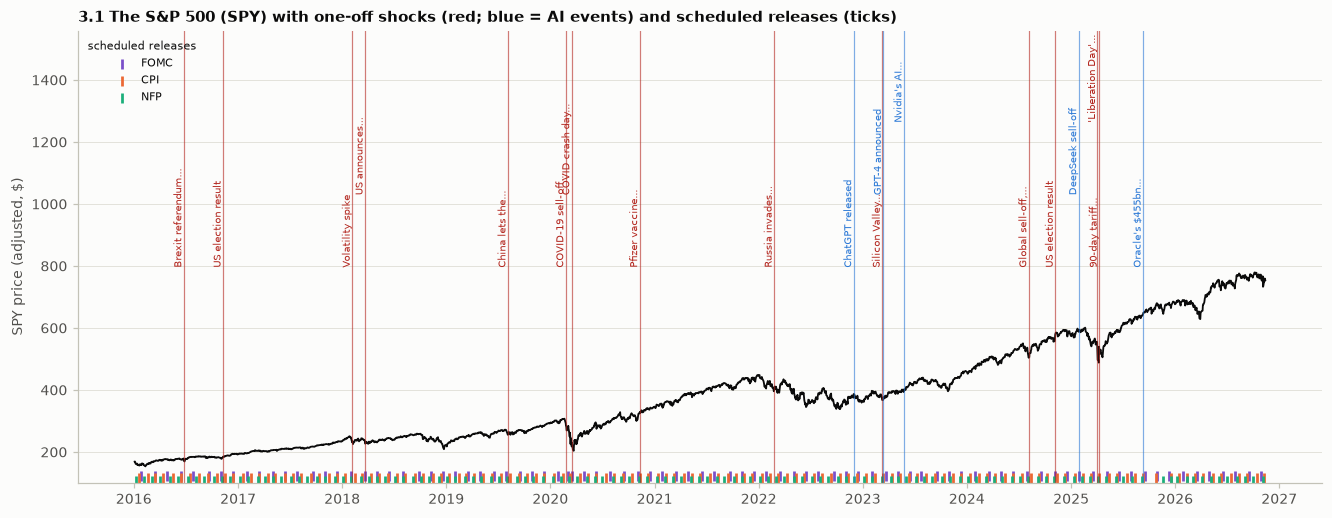

In [10]:
spy = prices[MARKET].loc[STUDY_START:]
fig, ax = plt.subplots(figsize=(12, 4.6), layout="constrained")
ax.plot(spy.index, spy, color=INK, lw=1.2)
ymin, ymax = spy.min(), spy.max()
shock_rows = events[events["event_type"] == "SHOCK"].drop_duplicates("day")
level, last_day = 0, None
for _, r in shock_rows.iterrows():
    color = "#2a78d6" if r["category"].startswith("ai") else HIGHLIGHT
    ax.axvline(r["day"], color=color, lw=0.8, alpha=0.6)
    # Shocks less than ~3 months apart get different label heights so the labels don't overlap.
    level = (level + 1) % 3 if last_day is not None and (r["day"] - last_day).days < 90 else 0
    last_day = r["day"]
    ax.text(r["day"], ymax * (1.02 + 0.30 * level), short_label(r["name"], 18), rotation=90, fontsize=6.5,
            va="bottom", ha="right", color=color)
for i, t in enumerate(["FOMC", "CPI", "NFP"]):
    d = events.loc[events["event_type"] == t, "day"]
    ax.scatter(d, np.full(len(d), ymin * (0.80 - 0.05 * i)), marker="|", s=40, color=TYPE_COLORS[t], label=t)
ax.set_ylim(ymin * 0.66, ymax * 2.0)
ax.set_ylabel("SPY price (adjusted, $)")
ax.legend(frameon=False, fontsize=7, loc="upper left", title="scheduled releases", title_fontsize=7)
year_axis(ax)
ax.grid(axis="y")
ax.set_title("3.1 The S&P 500 (SPY) with one-off shocks (red; blue = AI events) and scheduled releases (ticks)")
save(fig, "3_1_events_on_spy")
plt.show()

## 4. Q1: do events explain the strangest days?

The 1% most unusual days (Isolation Forest on residual z-scores, from `comovement_rules.ipynb`) are labelled with
every event on that day; a one-off shock counts within ±1 trading day because news often breaks the evening before.

**Is the match rate more than chance?** Rate decisions and data releases happen on about one day in eight, so some
unusual days fall on them by luck. The **event-date shift test** moves the *whole calendar* forward by a random number
of trading days (at least a month, wrapping around at the end) and counts the matches again, 1,000 times. Moving the
whole calendar keeps its rhythm (eight Fed meetings a year, monthly releases) and only breaks the link between events
and market days.

**A category for every unusual day.** Each day also gets one category, the first rule that applies: one-off shock
(±1 day) → scheduled release → **earnings reaction** (a company reporting that day is among the day's five largest
moves) → **market stress** (SPY's trailing 21-day volatility in its top 5%, as in March 2020) → **earnings day,
reporter quiet** → **unexplained**. The earnings and stress rules describe the days; they are not part of the test.

In [11]:
def shifted(mask, k):
    # Move a True/False day series forward by k trading days, wrapping around at the end.
    return np.roll(np.asarray(mask), k)


def widen(mask, tol):
    # True within +-tol trading days of any True day.
    m = np.asarray(mask, dtype=bool)
    out = m.copy()
    for k in range(1, tol + 1):
        out[k:] |= m[:-k]
        out[:-k] |= m[k:]
    return out


def match_share(top_pos, masks):
    hit = np.zeros(len(top_pos), dtype=bool)
    for m in masks:
        hit |= m[top_pos]
    return hit.mean()


def shift_test(top_pos, masks, n=N_SHIFTS):
    # Observed share of top days that match any of the masks, and the same share for random calendar shifts.
    observed = match_share(top_pos, masks)
    shifts = rng.integers(MIN_SHIFT, N_DAYS - MIN_SHIFT, size=n)
    null = np.array([match_share(top_pos, [shifted(m, k) for m in masks]) for k in shifts])
    return observed, null, float((null >= observed).mean())


def label_days(days):
    rows = []
    for d in days:
        p = POS[d]
        near = events[(events["event_type"] == "SHOCK") & ((events["pos"] - p).abs() <= SHOCK_TOLERANCE)]
        same = events[(events["event_type"] != "SHOCK") & (events["pos"] == p)]
        labels = list(same["event_type"]) + list(near["name"])
        if HAS_EARNINGS:
            reporters = list(earn_matrix.columns[earn_matrix.loc[d]])
            if reporters:
                labels.append("earnings: " + ", ".join(reporters))
        movers = zscores.loc[d].abs().sort_values(ascending=False).head(5).index
        rows.append({"date": d.date(), "anomaly": round(anomaly.loc[d], 3), "moves in basket": int(basket_size.loc[d]),
                     "events": "; ".join(labels) if labels else "(none in calendar)",
                     "largest residual moves (z)": ", ".join(f"{t} {zscores.loc[d, t]:+.1f}" for t in movers)})
    return pd.DataFrame(rows)


n_top = int(round(TOP_SHARE * N_DAYS))
top_days = anomaly.nlargest(n_top).index
top_pos = np.array([POS[d] for d in top_days])
shock_mask = widen(event_days["SHOCK"], SHOCK_TOLERANCE)
macro_mask = event_days["MACRO"].to_numpy()

obs_any, null_any, p_any = shift_test(top_pos, [macro_mask, shock_mask])
obs_macro, null_macro, p_macro = shift_test(top_pos, [macro_mask])
obs_shock, null_shock, p_shock = shift_test(top_pos, [shock_mask])

labelled = label_days(top_days)

# One category per unusual day (a description, not a test). The first rule that applies wins.
spy_vol_21 = market_returns.rolling(21).std().loc[DAYS]          # trailing: known on the day itself
stress_day = spy_vol_21 >= spy_vol_21.quantile(STRESS_Q)
CATEGORY_ORDER = ["one-off shock", "scheduled release", "earnings reaction", "market stress", "earnings day, reporter quiet",
                  "unexplained"]


def categorise(d):
    p = POS[d]
    reporters = set(earn_matrix.columns[earn_matrix.loc[d]]) if HAS_EARNINGS else set()
    top_movers = set(zscores.loc[d].abs().nlargest(5).index)
    if shock_mask[p]:
        return "one-off shock"                     # within +-1 day of a listed shock
    if macro_mask[p]:
        return "scheduled release"                 # FOMC decision, CPI or jobs report that day
    if reporters & top_movers:
        return "earnings reaction"                 # a company reporting that day is among the 5 largest moves
    if stress_day.loc[d]:
        return "market stress"                     # inside a high-volatility stretch (e.g. March 2020)
    if reporters:
        return "earnings day, reporter quiet"      # someone reported, but not among the 5 largest moves
    return "unexplained"


labelled.insert(1, "category", [categorise(d) for d in top_days])
labelled.to_csv(OUT_DIR / "top_unusual_days_labelled.csv", index=False)
category_counts = labelled["category"].value_counts().reindex(CATEGORY_ORDER, fill_value=0)
print("Category of each unusual day:", category_counts.to_dict())
KEY["q1_unusual_days"] = {"n_top_days": n_top,
              "share_matched_macro_or_shock": round(obs_any, 3), "null_mean": round(null_any.mean(), 3), "p": p_any,
              "share_matched_macro": round(obs_macro, 3), "null_mean_macro": round(null_macro.mean(), 3), "p_macro": p_macro,
              "share_matched_shock": round(obs_shock, 3), "null_mean_shock": round(null_shock.mean(), 3), "p_shock": p_shock,
              "categories": {k: int(v) for k, v in category_counts.items()},
              "unexplained_days": [str(d) for d in labelled.loc[labelled["category"] == "unexplained", "date"]]}
print(json.dumps(KEY["q1_unusual_days"], indent=1))
labelled

Category of each unusual day: {'one-off shock': 9, 'scheduled release': 0, 'earnings reaction': 6, 'market stress': 7, 'earnings day, reporter quiet': 1, 'unexplained': 4}
{
 "n_top_days": 27,
 "share_matched_macro_or_shock": 0.333,
 "null_mean": 0.138,
 "p": 0.002,
 "share_matched_macro": 0.074,
 "null_mean_macro": 0.126,
 "p_macro": 0.927,
 "share_matched_shock": 0.333,
 "null_mean_shock": 0.02,
 "p_shock": 0.0,
 "categories": {
  "one-off shock": 9,
  "scheduled release": 0,
  "earnings reaction": 6,
  "market stress": 7,
  "earnings day, reporter quiet": 1,
  "unexplained": 4
 },
 "unexplained_days": [
  "2020-11-04",
  "2017-06-09",
  "2017-12-04",
  "2017-11-29"
 ]
}


,date,category,anomaly,moves in basket,events,largest residual moves (z)
0,2020-11-09,one-off shock,0.613,68,Pfizer vaccine efficacy result; earnings: BRK-...,"AXP +11.4, BKNG +10.6, LOW -8.6, MA +8.1, COST..."
1,2020-03-19,earnings reaction,0.596,74,earnings: ACN,"AVGO +7.9, KO -5.9, SBUX +5.5, ACN +5.3, FDX +5.2"
2,2016-11-10,one-off shock,0.580,74,US election result (Trump),"PEP -6.6, BRK-B +6.4, WFC +6.4, GOOGL -5.6, JP..."
3,2026-11-04,earnings reaction,0.573,75,"earnings: AMD, AMGN, ANET, BKNG, CVS, EMR, MCD...","CVS -7.6, MMM +5.8, MCD +4.9, BRK-B +4.6, GEV ..."
4,2020-03-18,earnings reaction,0.571,72,earnings: FDX,"CVX -10.0, CSCO +7.0, FDX +6.5, GM -6.1, ANET ..."
5,2016-11-09,one-off shock,0.568,75,US election result (Trump),"PFE +10.0, GD +8.8, AMT -7.0, CAT +6.9, LLY +6.7"
6,2024-11-06,one-off shock,0.557,65,US election result (Trump); earnings: CVS,"GS +8.9, JPM +8.2, COF +7.7, MS +7.2, WFC +6.8"
7,2025-04-04,one-off shock,0.556,70,NFP; 'Liberation Day' tariffs announced (2 Apr...,"RTX -5.8, T -4.7, V -4.5, ABBV -4.5, PG -4.3"
8,2020-03-13,one-off shock,0.555,72,COVID crash day after the Fed's Sunday emergen...,"ORCL +9.8, ADBE +9.0, AXP +8.5, GS +8.1, JPM +6.4"
9,2020-11-04,unexplained,0.550,67,(none in calendar),"LLY +7.5, CAT -6.5, UNH +6.2, BMY +4.9, UBER +4.8"


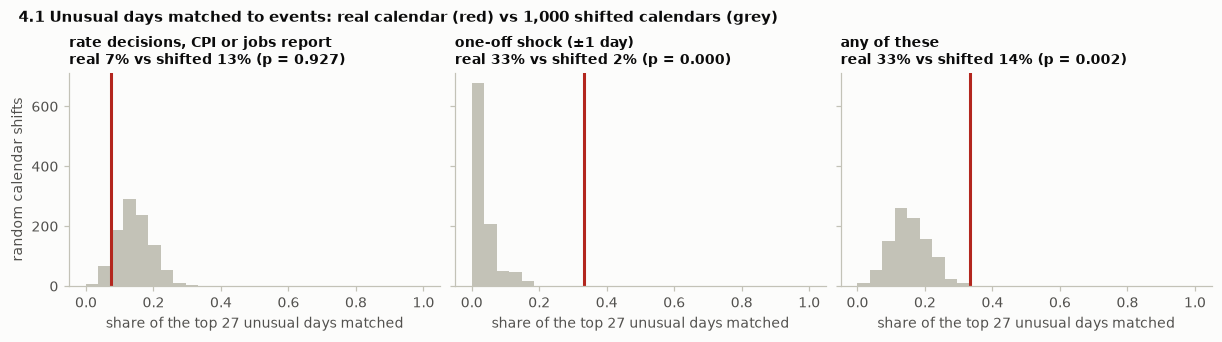

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), layout="constrained", sharey=True)
for ax, (title, obs, null, p) in zip(axes, [("rate decisions, CPI or jobs report", obs_macro, null_macro, p_macro),
                                            ("one-off shock (±1 day)", obs_shock, null_shock, p_shock),
                                            ("any of these", obs_any, null_any, p_any)]):
    ax.hist(null, bins=np.arange(0, 1.0001, 1 / n_top), color=AXIS)
    ax.axvline(obs, color=HIGHLIGHT, lw=2)
    ax.set_title(f"{title}\nreal {obs:.0%} vs shifted {null.mean():.0%} (p = {p:.3f})", fontsize=9)
    ax.set_xlabel(f"share of the top {n_top} unusual days matched")
axes[0].set_ylabel("random calendar shifts")
fig.suptitle("4.1 Unusual days matched to events: real calendar (red) vs 1,000 shifted calendars (grey)",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
save(fig, "4_1_unusual_days_shift_test")
plt.show()

**The AI events.** Where each AI event's day ranks among all days (1.00 = the most unusual day). AI product
launches carry no immediate business news; AI business news (guidance, a cheaper rival model, a backlog) does.

In [13]:
ai_rows = events[events["category"].isin(["ai_launch", "ai_business"])]
ai_table = pd.DataFrame({
    "event": ai_rows["name"].values,
    "kind": ai_rows["category"].values,
    "anomaly percentile": [round(float((anomaly <= anomaly.loc[d]).mean()), 3) for d in ai_rows["day"]],
    "moves in basket": [int(basket_size.loc[d]) for d in ai_rows["day"]],
}, index=ai_rows["day"].dt.date)
KEY["ai_events_anomaly_percentile"] = ai_table.set_index("event")["anomaly percentile"].to_dict()
ai_table

,event,kind,anomaly percentile,moves in basket
day,,,,
2022-11-30,ChatGPT released,ai_launch,0.595,31
2023-03-14,GPT-4 announced,ai_launch,0.589,29
2023-05-25,Nvidia's AI revenue guidance,ai_business,0.984,52
2025-01-27,DeepSeek sell-off,ai_business,0.995,73
2025-09-10,Oracle's $455bn cloud backlog,ai_business,0.921,32


## 5. Q2: who reacts to scheduled news, and to company news?

**5.1 Are event days more unusual?** Anomaly scores on each type's days against *quiet days* (no rate decision,
data release or shock within a day), one-sided Mann-Whitney test ("event days are more unusual"), with
Benjamini-Hochberg across the four types.

In [14]:
quiet = ~(event_days[["FOMC", "CPI", "NFP"]].any(axis=1).to_numpy() | widen(event_days["SHOCK"], 1))
anomaly_pct = anomaly.rank(pct=True)
rows = []
for t in EVENT_TYPES:
    on = event_days[t].to_numpy()
    p = mannwhitneyu(anomaly[on], anomaly[quiet], alternative="greater").pvalue
    rows.append({"type": t, "days": int(on.sum()), "median anomaly percentile": anomaly_pct[on].median(),
                 "share in top 5%": float((anomaly_pct[on] >= 0.95).mean()),
                 "median moves in basket": basket_size[on].median(), "p (vs quiet days)": p})
rows.append({"type": "quiet days", "days": int(quiet.sum()), "median anomaly percentile": anomaly_pct[quiet].median(),
             "share in top 5%": float((anomaly_pct[quiet] >= 0.95).mean()),
             "median moves in basket": basket_size[quiet].median(), "p (vs quiet days)": np.nan})
by_type = pd.DataFrame(rows).set_index("type")
by_type["significant (BH 5%)"] = False
by_type.loc[EVENT_TYPES, "significant (BH 5%)"] = benjamini_hochberg(by_type.loc[EVENT_TYPES, "p (vs quiet days)"])
by_type.to_csv(OUT_DIR / "unusualness_by_event_type.csv")
KEY["by_event_type"] = by_type.round(4).to_dict(orient="index")
by_type.round(3)

,days,median anomaly percentile,share in top 5%,median moves in basket,p (vs quiet days),significant (BH 5%)
type,,,,,,
FOMC,88,0.680,0.023,26.5,0.000,True
CPI,130,0.463,0.038,22.0,0.768,False
NFP,130,0.386,0.038,20.0,0.902,False
SHOCK,19,0.984,0.579,52.0,0.000,True
quiet days,2348,0.494,0.045,22.0,NaN,False


**5.2 Which sectors move on rate and data days?** For each sector: the share of its stocks making a major move on
event days, divided by the same share on quiet days (only stocks with enough history count). 1.0 = no different
from a quiet day. Intervals: 95% bootstrap over event days. Because the market has been removed, a ratio above 1
means the sector reacts *more than its usual market sensitivity explains*. The semiconductor stocks are shown as an
extra group.

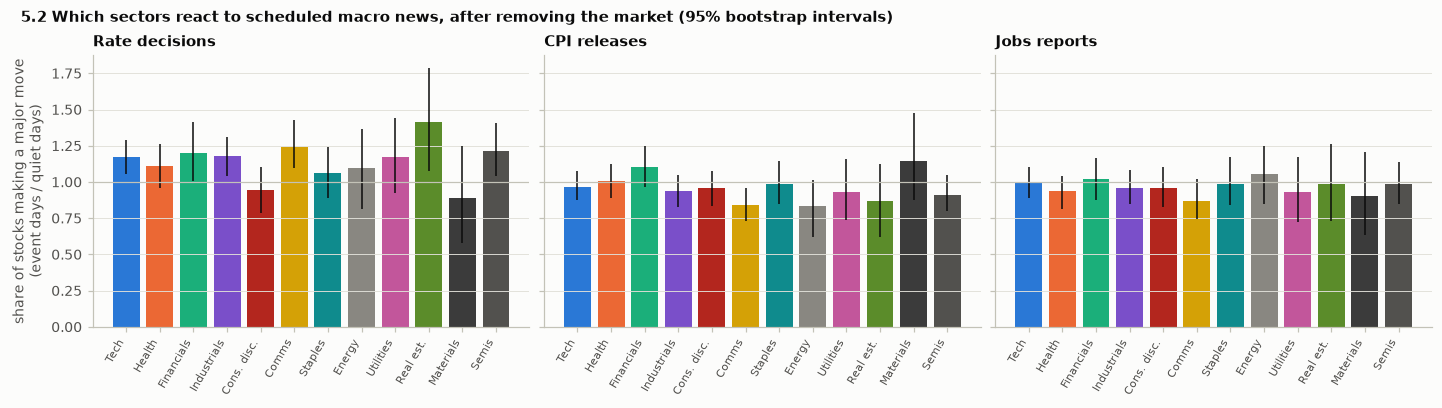

,event,sector,stocks,ratio,low,high,clearly above 1
0,FOMC,Information Technology,24,1.17,1.05,1.29,True
2,FOMC,Financials,15,1.20,1.01,1.42,True
3,FOMC,Industrials,14,1.18,1.04,1.31,True
5,FOMC,Communication Services,8,1.24,1.10,1.43,True
9,FOMC,Real Estate,1,1.41,1.08,1.78,True
11,FOMC,Semiconductors,9,1.21,1.04,1.41,True


In [15]:
move_any = pd.DataFrame({t: items[f"{t}_UP"] | items[f"{t}_DOWN"] for t in TICKERS})
GROUPS_Q2 = {s: stocks.loc[stocks["sector"] == s, "ticker"].tolist() for s in SECTORS} | {"Semiconductors": SEMIS}


def move_ratio(cols, on, n_boot=500):
    moved = move_any[cols].to_numpy().sum(axis=1)
    n_active = active[cols].to_numpy().sum(axis=1)
    rate = np.divide(moved, n_active, out=np.full(len(moved), np.nan), where=n_active > 0)
    base = np.nanmean(rate[quiet])
    ev = rate[on & np.isfinite(rate)]
    boot = np.array([rng.choice(ev, len(ev)).mean() for _ in range(n_boot)]) / base
    return ev.mean() / base, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


ratio_rows = []
for t in ["FOMC", "CPI", "NFP"]:
    on = event_days[t].to_numpy()
    for g, members in GROUPS_Q2.items():
        r, lo, hi = move_ratio(members, on)
        ratio_rows.append({"event": t, "sector": g, "stocks": len(members), "ratio": r, "low": lo, "high": hi,
                           "clearly above 1": lo > 1})
ratios = pd.DataFrame(ratio_rows)
ratios.to_csv(OUT_DIR / "move_ratio_by_sector.csv", index=False)
KEY["move_ratio_by_sector"] = {f"{r.event} {r.sector}": [round(r.ratio, 2), round(r.low, 2), round(r.high, 2)] for r in ratios.itertuples()}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained", sharey=True)
order = list(GROUPS_Q2)
colors = [SECTOR_COLORS.get(g, INK_SOFT) for g in order]
for ax, t in zip(axes, ["FOMC", "CPI", "NFP"]):
    sub = ratios[ratios["event"] == t].set_index("sector").loc[order]
    x = np.arange(len(order))
    ax.bar(x, sub["ratio"], color=colors)
    ax.vlines(x, sub["low"], sub["high"], color=INK, lw=1)
    ax.axhline(1, color=AXIS, lw=0.8)
    ax.set_xticks(x, [SHORT.get(g, g) for g in order], fontsize=7, rotation=60, ha="right")
    ax.set_title({"FOMC": "Rate decisions", "CPI": "CPI releases", "NFP": "Jobs reports"}[t])
    ax.grid(axis="y")
axes[0].set_ylabel("share of stocks making a major move\n(event days / quiet days)")
fig.suptitle("5.2 Which sectors react to scheduled macro news, after removing the market (95% bootstrap intervals)",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
save(fig, "5_2_move_ratio_by_sector")
plt.show()
ratios[ratios["clearly above 1"]].round(2)

**Which single stocks react most on rate-decision days?** Top 10 by move ratio (each stock's own rate, days with
enough history only).

In [16]:
fomc_on = event_days["FOMC"].to_numpy()
act = active.to_numpy()
mv = move_any.to_numpy()
on_rate = (mv & act)[fomc_on].sum(0) / np.maximum(act[fomc_on].sum(0), 1)
quiet_rate = (mv & act)[quiet].sum(0) / np.maximum(act[quiet].sum(0), 1)
stock_ratio = pd.Series(on_rate / quiet_rate, index=TICKERS).sort_values(ascending=False)
KEY["top_fomc_stocks"] = stock_ratio.head(10).round(2).to_dict()
stock_ratio.head(10).round(2).to_frame("FOMC move ratio").assign(sector=lambda d: [GROUP_OF[t] for t in d.index])

,FOMC move ratio,sector
GEV,1.87,Industrials
TMUS,1.76,Communication Services
CVS,1.74,Health Care
BA,1.63,Industrials
AMD,1.56,Information Technology
JPM,1.52,Financials
ANET,1.51,Information Technology
ORCL,1.49,Information Technology
USB,1.47,Financials
ADBE,1.46,Information Technology


**5.3 Events as items: association rules mined on event days.** An event becomes an item (`FOMC_DAY`,
`EARN_NVDA`, ...). Rules with an event on the left are mined from the **conditional database**: only the baskets of
days that contain the left-hand side, which is how FP-Growth itself grows itemsets. For a left-hand side A and a
right-hand side X: confidence = share of A's days on which X happened; lift = confidence / share of *all* days on
which X happened; a one-sided Fisher exact test asks whether X happens on A's days more than chance, and
Benjamini-Hochberg counts every right-hand side that could have been tested (every single item and every pair).
**Chance check:** the same mining on event days moved by random calendar shifts.

In [17]:
ALL_ITEMS = list(items.columns)
N_POSSIBLE_RHS = len(ALL_ITEMS) + len(ALL_ITEMS) * (len(ALL_ITEMS) - 1) // 2


def mine_given(mask, name, basket=items, exclude=()):
    # Rules "name -> X" from the baskets of the days in `mask`. X has 1 or 2 items and excludes `exclude`.
    mask = np.asarray(mask, dtype=bool)
    n_a = int(mask.sum())
    if n_a < COND_MIN_COUNT:
        return pd.DataFrame()
    cols = [c for c in basket.columns if c not in set(exclude)]
    cond = basket.loc[mask, cols]
    min_sup = max(COND_MIN_SUPPORT, COND_MIN_COUNT / n_a)
    sets = fpgrowth(cond, min_support=min_sup, use_colnames=True, max_len=2)
    if sets.empty:
        return pd.DataFrame()
    full = basket[cols].to_numpy(dtype=bool)
    col_of = {c: i for i, c in enumerate(cols)}
    out = []
    for sup_cond, s in zip(sets["support"], sets["itemsets"]):
        idx = [col_of[c] for c in s]
        n_x = int(full[:, idx].all(axis=1).sum())
        n_ax = int(round(sup_cond * n_a))
        lift = sup_cond / (n_x / len(basket))
        if lift < COND_MIN_LIFT:
            continue
        out.append({"rule": f"{name} -> {', '.join(sorted(s))}", "lhs": name, "rhs": ", ".join(sorted(s)),
                    "lhs days": n_a, "joint days": n_ax, "confidence": sup_cond, "lift": lift,
                    "p": hypergeom.sf(n_ax - 1, len(basket), n_a, n_x)})
    return pd.DataFrame(out)


def mine_event_items(day_masks, n_tests_per_lhs=N_POSSIBLE_RHS):
    # day_masks: {lhs name: (mask, items to exclude from the right-hand side)}
    rules = pd.concat([mine_given(m, n, exclude=ex) for n, (m, ex) in day_masks.items()], ignore_index=True)
    if rules.empty:
        return rules
    rules["significant"] = benjamini_hochberg(rules["p"], n_tests=n_tests_per_lhs * len(day_masks))
    return rules.sort_values("lift", ascending=False).reset_index(drop=True)


macro_lhs = {f"{t}_DAY": (event_days[t].to_numpy(), ()) for t in ["FOMC", "CPI", "NFP"]}
macro_rules = mine_event_items(macro_lhs)
n_shift_checks = 20
chance_counts = []
for k in rng.integers(MIN_SHIFT, N_DAYS - MIN_SHIFT, size=n_shift_checks):
    r = mine_event_items({n: (shifted(m, k), ex) for n, (m, ex) in macro_lhs.items()})
    chance_counts.append(len(r))
KEY["macro_rules"] = {"rules": len(macro_rules),
                      "significant": int(macro_rules["significant"].sum()) if len(macro_rules) else 0,
                      "rules_on_shifted_calendars_mean": float(np.mean(chance_counts))}
print(json.dumps(KEY["macro_rules"], indent=1))
macro_rules.to_csv(OUT_DIR / "event_rules_macro.csv", index=False)
macro_rules.head(15).round(3)

{
 "rules": 5,
 "significant": 0,
 "rules_on_shifted_calendars_mean": 0.05
}


,rule,lhs,rhs,lhs days,joint days,confidence,lift,p,significant
0,FOMC_DAY -> AMD_UP,FOMC_DAY,AMD_UP,88,23,0.261,1.920,0.001,False
1,FOMC_DAY -> DUK_DOWN,FOMC_DAY,DUK_DOWN,88,25,0.284,1.889,0.001,False
2,FOMC_DAY -> USB_DOWN,FOMC_DAY,USB_DOWN,88,22,0.250,1.793,0.004,False
3,FOMC_DAY -> AMAT_UP,FOMC_DAY,AMAT_UP,88,22,0.250,1.779,0.004,False
4,FOMC_DAY -> AMT_DOWN,FOMC_DAY,AMT_DOWN,88,22,0.250,1.775,0.004,False


**5.4 Earnings spillover.** For each company and direction, the left-hand side is "this company reported and made a
major move that way", e.g. `{EARN_NVDA, NVDA_UP}`. The key comparison: does an **earnings** move pull the company's
sector along more than an **ordinary** major move of the same stock on a day without its earnings? For every company
*T* and every other stock *P* (only days when *P* has enough history):
spillover lift = P(P moves the same way | T's move) / P(P moves that way). We report the mean over pairs in the
**same sector** and in **different sectors**, and each sector's own-sector value.

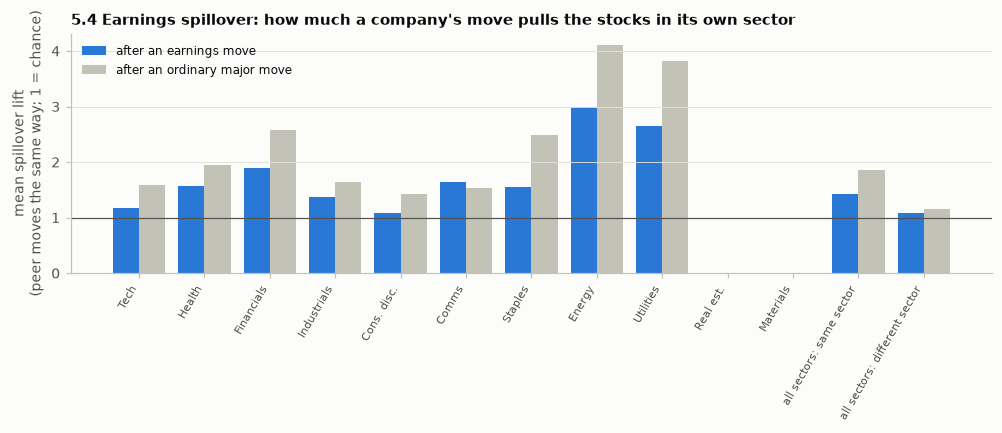

,after earnings move,after ordinary move
from,,
Information Technology,1.18,1.59
Health Care,1.57,1.95
Financials,1.89,2.57
Industrials,1.38,1.64
Consumer Discretionary,1.08,1.42
Communication Services,1.63,1.53
Consumer Staples,1.56,2.48
Energy,2.99,4.10
Utilities,2.65,3.82


,rule,lhs,rhs,lhs days,joint days,confidence,lift,p,significant,lift on ordinary move days,earnings adds
0,"EARN_BMY, BMY_DOWN -> META_UP, NOW_DOWN","EARN_BMY, BMY_DOWN","META_UP, NOW_DOWN",17,5,0.294,36.537,0.0,True,0.415,36.122
1,"EARN_LLY, LLY_DOWN -> MMM_DOWN, UPS_UP","EARN_LLY, LLY_DOWN","MMM_DOWN, UPS_UP",18,5,0.278,34.508,0.0,True,0.952,33.556
2,"EARN_HD, HD_DOWN -> LOW_DOWN, MDT_UP","EARN_HD, HD_DOWN","LOW_DOWN, MDT_UP",13,6,0.462,32.343,0.0,True,3.337,29.006
5,"EARN_XOM, XOM_DOWN -> AAPL_DOWN, AMZN_UP","EARN_XOM, XOM_DOWN","AAPL_DOWN, AMZN_UP",16,6,0.375,26.970,0.0,True,1.002,25.969
9,"EARN_GD, GD_DOWN -> AMGN_DOWN, UPS_DOWN","EARN_GD, GD_DOWN","AMGN_DOWN, UPS_DOWN",16,6,0.375,24.402,0.0,True,1.914,22.488
15,"EARN_DHR, DHR_UP -> GE_UP, TMO_UP","EARN_DHR, DHR_UP","GE_UP, TMO_UP",18,6,0.333,23.359,0.0,True,2.695,20.664
20,"EARN_ANET, ANET_DOWN -> DIS_UP, EMR_UP","EARN_ANET, ANET_DOWN","DIS_UP, EMR_UP",17,6,0.353,22.432,0.0,True,0.519,21.913
24,"EARN_META, META_UP -> TXN_DOWN, V_DOWN","EARN_META, META_UP","TXN_DOWN, V_DOWN",22,7,0.318,20.705,0.0,True,0.718,19.987
25,"EARN_V, V_UP -> BA_DOWN, MA_UP","EARN_V, V_UP","BA_DOWN, MA_UP",18,6,0.333,20.705,0.0,True,4.338,16.366
27,"EARN_V, V_UP -> MA_UP, TXN_DOWN","EARN_V, V_UP","MA_UP, TXN_DOWN",18,7,0.389,20.439,0.0,True,5.005,15.434


In [18]:
if HAS_EARNINGS:
    lhs = {}
    for t in TICKERS:
        for d in ["UP", "DOWN"]:
            lhs[f"EARN_{t}, {t}_{d}"] = ((earn_matrix[t] & items[f"{t}_{d}"]).to_numpy(), (f"{t}_UP", f"{t}_DOWN"))
    earn_rules = mine_event_items(lhs)

    # The same right-hand side after the same company's major move on a day WITHOUT its earnings (+-1 day).
    def plain_lift(lhs_name, rhs):
        t, d = lhs_name.split(", ")[1].rsplit("_", 1)
        on = items[f"{t}_{d}"].to_numpy() & ~widen(earn_matrix[t].to_numpy(), 1)
        x = items[rhs.split(", ")].to_numpy().all(axis=1)
        return x[on].mean() / x.mean() if on.sum() and x.mean() else np.nan

    if len(earn_rules):
        earn_rules["lift on ordinary move days"] = [plain_lift(l, r) for l, r in zip(earn_rules["lhs"], earn_rules["rhs"])]
        earn_rules["earnings adds"] = earn_rules["lift"] - earn_rules["lift on ordinary move days"]
    earn_rules.to_csv(OUT_DIR / "event_rules_earnings.csv", index=False)

    ITEM = {(t, d): items[f"{t}_{d}"].to_numpy() for t in TICKERS for d in ["UP", "DOWN"]}
    ACT = {t: active[t].to_numpy() for t in TICKERS}
    BASE = {(t, d): ITEM[(t, d)][ACT[t]].mean() for t in TICKERS for d in ["UP", "DOWN"]}

    def spillover(kind):
        # kind = "earn" (moves on earnings days) or "plain" (major moves on days without that company's earnings)
        rows = []
        for t in TICKERS:
            e = earn_matrix[t].to_numpy()
            for d in ["UP", "DOWN"]:
                on = ITEM[(t, d)] & e if kind == "earn" else ITEM[(t, d)] & ~widen(e, 1)
                if on.sum() < COND_MIN_COUNT:
                    continue
                for p_ in TICKERS:
                    if p_ == t or BASE[(p_, d)] == 0:
                        continue
                    mask = on & ACT[p_]
                    if mask.sum() < COND_MIN_COUNT:
                        continue
                    rows.append({"from": GROUP_OF[t], "to": GROUP_OF[p_], "same sector": GROUP_OF[t] == GROUP_OF[p_],
                                 "lift": ITEM[(p_, d)][mask].mean() / BASE[(p_, d)]})
        return pd.DataFrame(rows)

    sp_earn, sp_plain = spillover("earn"), spillover("plain")
    spill = pd.DataFrame({
        "after earnings move": sp_earn[sp_earn["same sector"]].groupby("from")["lift"].mean(),
        "after ordinary move": sp_plain[sp_plain["same sector"]].groupby("from")["lift"].mean(),
    }).reindex(SECTORS)
    spill.loc["all sectors: same sector"] = [sp_earn.loc[sp_earn["same sector"], "lift"].mean(), sp_plain.loc[sp_plain["same sector"], "lift"].mean()]
    spill.loc["all sectors: different sector"] = [sp_earn.loc[~sp_earn["same sector"], "lift"].mean(), sp_plain.loc[~sp_plain["same sector"], "lift"].mean()]
    spill.to_csv(OUT_DIR / "earnings_spillover_by_sector.csv")
    sig = earn_rules[earn_rules["significant"]] if len(earn_rules) else earn_rules
    KEY["earnings"] = {"earnings_rules": len(earn_rules), "significant": int(len(sig)),
                       "significant_beating_ordinary_days": int((sig["earnings adds"] > 0).sum()) if len(sig) else 0,
                       "spillover": spill.round(2).to_dict(orient="index")}

    fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
    x = np.arange(len(spill))
    ax.bar(x - 0.2, spill["after earnings move"], width=0.4, color="#2a78d6", label="after an earnings move")
    ax.bar(x + 0.2, spill["after ordinary move"], width=0.4, color=AXIS, label="after an ordinary major move")
    ax.axhline(1, color=INK_SOFT, lw=0.8)
    ax.set_xticks(x, [SHORT.get(s, s) for s in spill.index], rotation=60, ha="right", fontsize=7.5)
    ax.set_ylabel("mean spillover lift\n(peer moves the same way; 1 = chance)")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(axis="y")
    ax.set_title("5.4 Earnings spillover: how much a company's move pulls the stocks in its own sector")
    save(fig, "5_4_earnings_spillover")
    plt.show()
    display(spill.round(2))
    display(earn_rules[earn_rules["significant"]].head(15).round(3))
else:
    print("Skipped: no earnings file.")

## 6. Q3: when events change co-movement, does the change last?

**6.1 Structure breaks.** Every week, compare the co-movement structure of the half-year before the date with the
half-year after it: compute the pair lift of every pair of stocks in each half (pairs need moves in both halves),
and score 1 − correlation between the two sets of lifts (on a log scale). 0 = same structure, higher = more change.

In [19]:
PAIR_I, PAIR_J = np.triu_indices(len(TICKERS), 1)
UP_COLS = [f"{t}_UP" for t in TICKERS]
DOWN_COLS = [f"{t}_DOWN" for t in TICKERS]


def pair_lift_vector(basket, pairs=(PAIR_I, PAIR_J)):
    # Log2 pair lift of "both made a major move in the same direction on the same day", one value per pair.
    up = basket[UP_COLS].to_numpy(dtype=float)
    down = basket[DOWN_COLS].to_numpy(dtype=float)
    together = (up.T @ up + down.T @ down) / len(basket)
    chance = np.outer(up.mean(0), up.mean(0)) + np.outer(down.mean(0), down.mean(0))
    lift = np.divide(together, chance, out=np.full_like(together, np.nan), where=chance > 0)
    return np.log2(np.clip(lift[pairs], 0.25, 8))


def similarity(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[ok], b[ok])[0, 1]) if ok.sum() > 10 else np.nan


class LiftCache:
    # Pair-lift vectors of SPAN-day windows, cached by start position (many windows are reused).
    def __init__(self, basket, pairs=(PAIR_I, PAIR_J)):
        self.basket, self.pairs, self.cache = basket, pairs, {}

    def __call__(self, start):
        if start not in self.cache:
            self.cache[start] = pair_lift_vector(self.basket.iloc[start:start + SPAN], self.pairs)
        return self.cache[start]


def local_break_series(basket, step=GRID_STEP):
    lv = LiftCache(basket)
    grid = list(range(SPAN, len(basket) - SPAN + 1, step))
    return pd.Series([1 - similarity(lv(p - SPAN), lv(p)) for p in grid], index=basket.index[grid], name="break score")


breaks = local_break_series(items)
breaks.to_csv(OUT_DIR / "local_break_score.csv")


def find_peaks(series, q=0.9, gap=PEAK_GAP // GRID_STEP):
    # Local maxima above the q-quantile, at least `gap` grid steps apart (largest first).
    cut = series.quantile(q)
    peaks = []
    for d, v in series.sort_values(ascending=False).items():
        if v < cut:
            break
        i = series.index.get_loc(d)
        if all(abs(i - series.index.get_loc(p)) >= gap for p in peaks):
            peaks.append(d)
    return sorted(peaks)


peaks = find_peaks(breaks)
rows = []
for d in peaks:
    p = POS[d]
    near = events[(events["event_type"] == "SHOCK") & ((events["pos"] - p).abs() <= NEAR)]
    lo, hi = max(0, p - NEAR), min(N_DAYS, p + NEAR + 1)
    worst = anomaly.iloc[lo:hi].idxmax()
    movers = zscores.loc[worst].abs().sort_values(ascending=False).head(4).index
    rows.append({"break date": d.date(), "break score": round(breaks.loc[d], 3),
                 "percentile": round(float((breaks <= breaks.loc[d]).mean()), 3),
                 "shocks within ±21 days": "; ".join(f"{n} ({x.date()})" for n, x in zip(near["name"], near["day"])) or "-",
                 "most unusual day nearby": f"{worst.date()}: " + ", ".join(f"{t} {zscores.loc[worst, t]:+.1f}" for t in movers)})
peak_table = pd.DataFrame(rows)
peak_table.to_csv(OUT_DIR / "break_peaks_with_events.csv", index=False)
KEY["break_peaks"] = peak_table[["break date", "break score", "shocks within ±21 days"]].astype(str).to_dict(orient="records")
peak_table

,break date,break score,percentile,shocks within ±21 days,most unusual day nearby
0,2016-10-26,0.765,0.998,US election result (Trump) (2016-11-09),"2016-11-10: PEP -6.6, BRK-B +6.4, WFC +6.4, GO..."
1,2017-01-24,0.731,0.932,-,"2017-01-17: ANET -7.6, JPM -2.8, QCOM -2.7, US..."
2,2017-06-09,0.799,1.000,-,"2017-06-09: PFE +6.7, CRM -6.0, AMAT -5.5, ANE..."
3,2018-01-05,0.755,0.992,"Volatility spike ('Volmageddon'), Dow -1,175 (...","2018-02-05: AAPL +4.2, KO -4.0, WFC -3.8, MMM ..."
4,2018-04-04,0.728,0.907,US announces tariffs on Chinese imports (Secti...,"2018-04-26: T -6.5, V +5.8, AMD +4.9, META +4.8"
5,2020-02-07,0.741,0.974,COVID-19 sell-off begins (outbreak in Italy) (...,"2020-03-09: COP -11.0, CVX -9.8, EMR -9.2, USB..."
6,2020-05-05,0.731,0.930,-,"2020-05-26: GS +3.4, MS +3.2, BNY +2.7, WFC +2.4"


**Do shocks land on breaks more than chance?** Each shock's break score (at the nearest weekly point) as a
percentile of all weeks, averaged over the shocks, against the same average for the shocks' dates moved
together by a random shift. Rate decisions and data releases are not tested here: one happens every couple of
weeks, so every half-year window contains many of them.

{
 "mean_break_percentile_at_shocks": 0.566,
 "null_mean": 0.5,
 "p": 0.194,
 "n_shocks_tested": 18
}


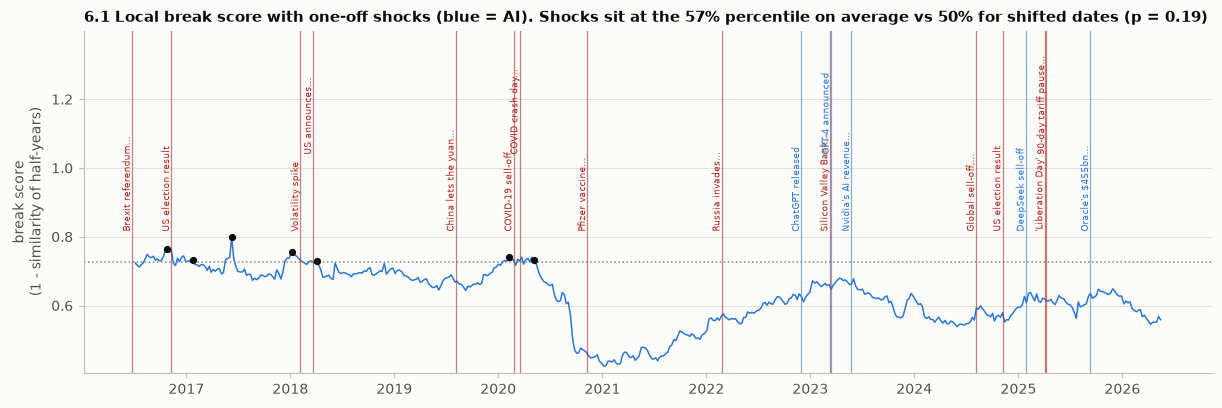

,break percentile,event
2016-11-09,0.994,US election result (Trump)
2018-02-05,0.940,"Volatility spike ('Volmageddon'), Dow -1,175"
2018-03-22,0.909,US announces tariffs on Chinese imports (Secti...
2019-08-05,0.622,China lets the yuan fall below 7 per dollar; w...
2020-02-24,0.942,COVID-19 sell-off begins (outbreak in Italy)
2020-03-16,0.913,COVID crash day after the Fed's Sunday emergen...
2020-11-09,0.072,Pfizer vaccine efficacy result
2022-02-24,0.262,Russia invades Ukraine
2022-11-30,0.467,ChatGPT released
2023-03-10,0.586,Silicon Valley Bank collapse


In [20]:
def shock_break_test(series, shock_days, n=N_SHIFTS):
    pct = series.rank(pct=True).to_numpy()
    grid_pos = np.array([POS[d] for d in series.index])
    shock_pos = np.array([POS[d] for d in shock_days])
    usable = (shock_pos >= grid_pos[0]) & (shock_pos <= grid_pos[-1])
    shock_pos = shock_pos[usable]

    def mean_pct(positions):
        idx = np.abs(grid_pos[None, :] - positions[:, None]).argmin(axis=1)
        return pct[idx].mean()

    observed = mean_pct(shock_pos)
    span = grid_pos[-1] - grid_pos[0]
    null = np.array([mean_pct(grid_pos[0] + (shock_pos - grid_pos[0] + k) % span)
                     for k in rng.integers(MIN_SHIFT, span - MIN_SHIFT, size=n)])
    per_shock = {d.date(): round(float(pct[np.abs(grid_pos - POS[d]).argmin()]), 3)
                 for d, ok in zip(shock_days, usable) if ok}
    return observed, null, float((null >= observed).mean()), per_shock


shock_days_list = list(events.loc[events["event_type"] == "SHOCK", "day"])
obs_b, null_b, p_b, per_shock = shock_break_test(breaks, shock_days_list)
KEY["q3_shocks_vs_breaks"] = {"mean_break_percentile_at_shocks": round(obs_b, 3), "null_mean": round(null_b.mean(), 3), "p": p_b,
                    "n_shocks_tested": len(per_shock)}
print(json.dumps(KEY["q3_shocks_vs_breaks"], indent=1))

fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(breaks.index, breaks, color="#2a78d6", lw=1)
ax.axhline(breaks.quantile(0.9), color=MUTED, ls=":", lw=1)
for d in peaks:
    ax.scatter([d], [breaks.loc[d]], color=INK, s=14, zorder=4)
ymax = breaks.max()
last_day = None
level = 0
for _, r in events[events["event_type"] == "SHOCK"].drop_duplicates("day").iterrows():
    color = "#2a78d6" if r["category"].startswith("ai") else HIGHLIGHT
    ax.axvline(r["day"], color=color, lw=0.8, alpha=0.6)
    # Shocks closer than ~2 months alternate between two label heights so the labels don't overlap.
    level = 1 - level if last_day is not None and (r["day"] - last_day).days < 60 else 0
    last_day = r["day"]
    ax.text(r["day"], ymax * (1.02 + 0.28 * level), short_label(r["name"], 20), rotation=90, fontsize=6,
            va="bottom", ha="right", color=color)
ax.set_ylabel("break score\n(1 - similarity of half-years)")
ax.set_ylim(top=ymax * 1.75)
year_axis(ax)
ax.grid(axis="y")
ax.set_title(f"6.1 Local break score with one-off shocks (blue = AI). Shocks sit at the {obs_b:.0%} percentile on "
             f"average vs {null_b.mean():.0%} for shifted dates (p = {p_b:.2f})")
save(fig, "6_1_local_breaks_and_shocks")
plt.show()
shock_only = events[events["event_type"] == "SHOCK"].drop_duplicates("day")
shock_names = pd.Series(shock_only["name"].to_numpy(), index=shock_only["day"].dt.date)
pd.Series(per_shock, name="break percentile").to_frame().assign(event=[shock_names[d] for d in per_shock])

**6.2 Do changes last? Recovery curves.**

For each one-off shock, take the half-year **before** it as the "normal" structure. Then compare it with
half-year windows starting 0, 21, 42, ... 504 trading days **after** it (up to two years). Similarity = the
correlation of the pair lifts, as in 6.1.

Similarity falls with distance even without any event, because the market drifts. So every curve is compared with
the **normal drift**: the same calculation started at every month of the sample. The plotted value is the gap to
normal drift in standard deviations: 0 = an ordinary month, −1 = one standard deviation less similar than usual.

**Reading a curve.** A dip at the start that comes back to 0 = **temporary** break. A dip that stays = **lasting**
change. No dip = **no break**. Rule used (written down before running):

* no break: the lowest value in the first quarter (offsets 0–63) is above −1;
* temporary: early dip below −1, and the mean over the second year (offsets 252–504) is above −0.5;
* lasting: early dip below −1, and the second-year mean is −1 or lower;
* partial: anything in between; too recent: less than one year of data after the event; too early: the event
  is less than half a year after the first basket, so there is no "before" window.

In [21]:
def recovery_curves(basket, event_days_, pairs=(PAIR_I, PAIR_J)):
    lv = LiftCache(basket, pairs)
    n = len(basket)

    def curve(p):
        if p - SPAN < 0:
            return [np.nan] * len(H2_OFFSETS)
        pre = lv(p - SPAN)
        return [similarity(pre, lv(p + k)) if p + k + SPAN <= n else np.nan for k in H2_OFFSETS]

    normal_starts = range(SPAN, n - SPAN, 21)
    normal = pd.DataFrame([curve(p) for p in normal_starts], columns=H2_OFFSETS)
    mu, sd = normal.mean(), normal.std()
    ev = {d: (np.array(curve(POS[d])) - mu.to_numpy()) / sd.to_numpy() for d in event_days_}
    return pd.DataFrame(ev, index=H2_OFFSETS).T, mu, sd


def classify(z):
    early_vals = z[[k for k in H2_OFFSETS if k <= 63]].to_numpy()
    if not np.isfinite(early_vals).any():
        return "too early (no half-year before)", np.nan, np.nan
    early = np.nanmin(early_vals)
    late_cols = [k for k in H2_OFFSETS if 252 <= k <= 504]
    late_vals = z[late_cols].to_numpy()
    if np.isfinite(late_vals).sum() < 4:
        return "too recent", early, np.nan
    late = np.nanmean(late_vals)
    if early > -1:
        return "no break", early, late
    if late > -0.5:
        return "temporary", early, late
    if late <= -1:
        return "lasting", early, late
    return "partial", early, late


shock_rows = events[events["event_type"] == "SHOCK"].drop_duplicates("day")
curves, normal_mu, normal_sd = recovery_curves(items, list(shock_rows["day"]))
ai_pairs = tuple(np.array(x) for x in zip(*[(i, j) for i, j in zip(PAIR_I, PAIR_J)
                                             if TICKERS[i] in SEMIS or TICKERS[j] in SEMIS]))
curves_ai, _, _ = recovery_curves(items, list(shock_rows["day"]), pairs=ai_pairs)

h2 = []
for (_, r), (d, z) in zip(shock_rows.iterrows(), curves.iterrows()):
    label, early, late = classify(z)
    label_ai, early_ai, late_ai = classify(curves_ai.loc[d])
    h2.append({"date": d.date(), "event": r["name"], "category": r["category"],
               "result (all pairs)": label, "early dip": early, "second-year mean": late,
               "result (pairs with a semiconductor stock)": label_ai, "early dip (semis)": early_ai, "second-year mean (semis)": late_ai})
h2 = pd.DataFrame(h2)
h2.to_csv(OUT_DIR / "recovery_classification.csv", index=False)
KEY["q3_recovery_all_pairs"] = h2["result (all pairs)"].value_counts().to_dict()
KEY["q3_recovery_semi_pairs"] = h2["result (pairs with a semiconductor stock)"].value_counts().to_dict()
KEY["q3_recovery_by_event"] = {f"{r.date} {r.event}": [r._4, r._7] for r in h2.itertuples()}
print("All pairs:", KEY["q3_recovery_all_pairs"])
print("Pairs with a semiconductor stock:", KEY["q3_recovery_semi_pairs"])
h2.round(2)

All pairs: {'no break': 10, 'too recent': 3, 'lasting': 2, 'temporary': 2, 'too early (no half-year before)': 1, 'partial': 1}
Pairs with a semiconductor stock: {'no break': 9, 'partial': 3, 'too recent': 3, 'temporary': 2, 'too early (no half-year before)': 1, 'lasting': 1}


,date,event,category,result (all pairs),early dip,second-year mean,result (pairs with a semiconductor stock),early dip (semis),second-year mean (semis)
0,2016-06-24,Brexit referendum result,geopolitical,too early (no half-year before),NaN,NaN,too early (no half-year before),NaN,NaN
1,2016-11-09,US election result (Trump),policy,lasting,-1.92,-1.42,partial,-1.76,-0.58
2,2018-02-05,"Volatility spike ('Volmageddon'), Dow -1,175",market,lasting,-1.30,-1.35,partial,-1.76,-0.63
3,2018-03-22,US announces tariffs on Chinese imports (Secti...,policy,partial,-1.20,-0.99,temporary,-1.48,-0.13
4,2019-08-05,China lets the yuan fall below 7 per dollar; w...,policy,no break,-0.87,-0.22,lasting,-1.54,-1.20
5,2020-02-24,COVID-19 sell-off begins (outbreak in Italy),health,temporary,-1.48,0.06,partial,-2.58,-0.54
6,2020-03-16,COVID crash day after the Fed's Sunday emergen...,health,temporary,-1.50,0.20,temporary,-1.93,0.62
7,2020-11-09,Pfizer vaccine efficacy result,health,no break,1.79,0.95,no break,-0.72,-0.59
8,2022-02-24,Russia invades Ukraine,geopolitical,no break,0.37,0.90,no break,0.17,0.81
9,2022-11-30,ChatGPT released,ai_launch,no break,-0.13,0.08,no break,0.14,0.64


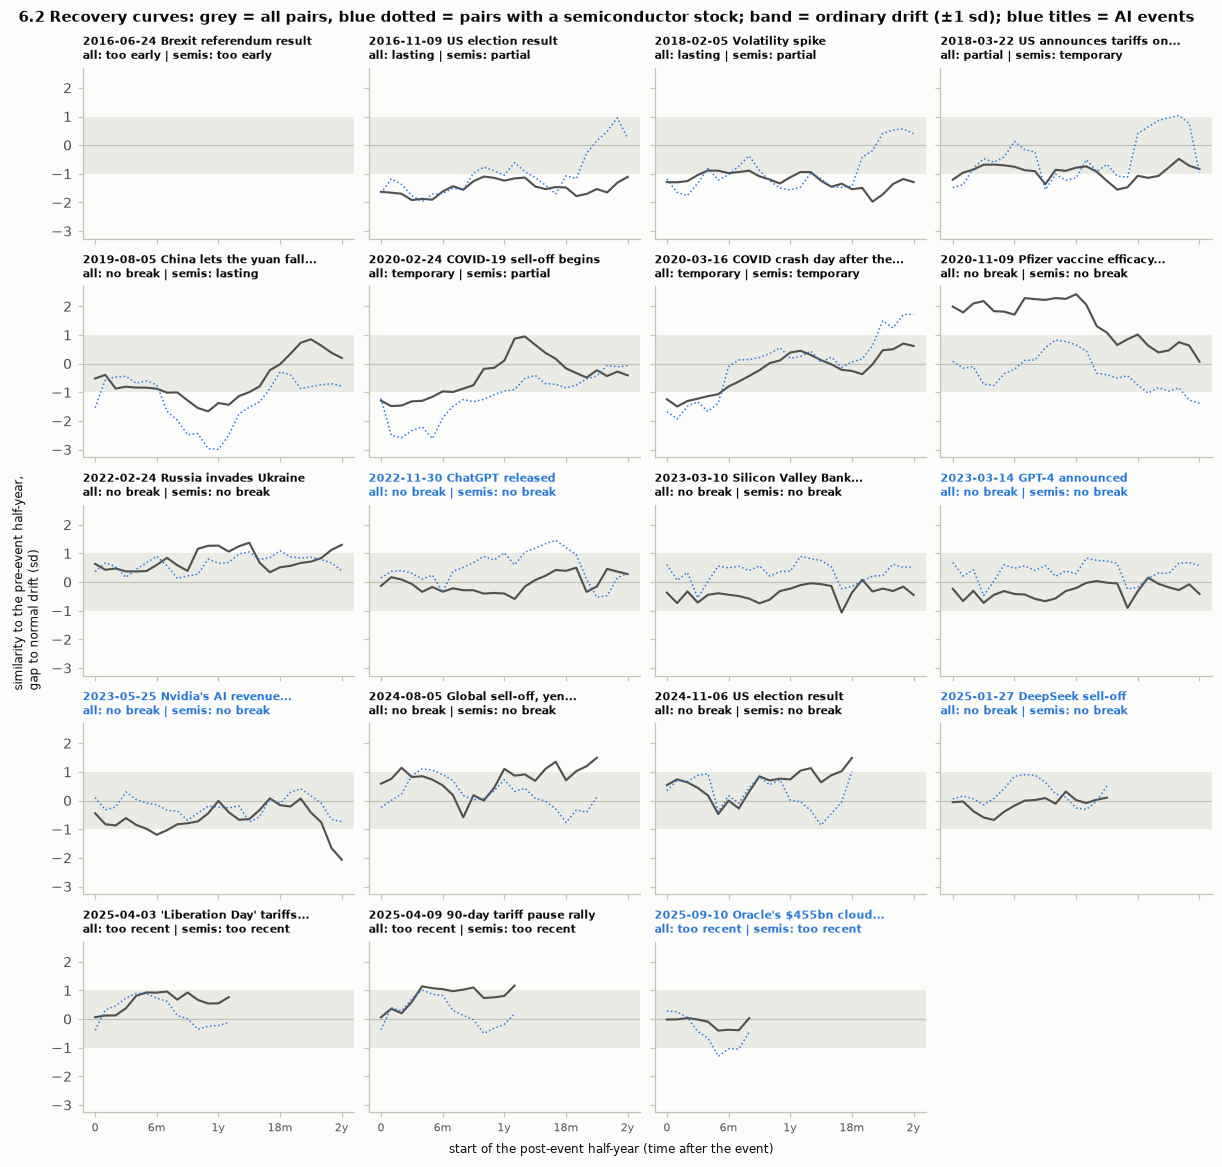

In [22]:
n = len(curves)
ncol = 4
fig, axes = plt.subplots(int(np.ceil(n / ncol)), ncol, figsize=(11, 2.1 * np.ceil(n / ncol)), sharex=True, sharey=True,
                         layout="constrained")
for ax, (d, z), (_, r) in zip(axes.flat, curves.iterrows(), h2.iterrows()):
    ax.axhspan(-1, 1, color=GRID, alpha=0.6, lw=0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.plot(H2_OFFSETS, z.to_numpy(), color=INK_SOFT, lw=1.4)
    ax.plot(H2_OFFSETS, curves_ai.loc[d].to_numpy(), color="#2a78d6", lw=1, ls=":")
    ai_event = r["category"].startswith("ai")
    ax.set_title(f"{d.date()} {short_label(r['event'], 26)}\nall: {r['result (all pairs)'].split(' (')[0]} | "
                 f"semis: {r['result (pairs with a semiconductor stock)'].split(' (')[0]}", fontsize=7.5,
                 color="#2a78d6" if ai_event else INK)
    ax.set_xticks([0, 126, 252, 378, 504], ["0", "6m", "1y", "18m", "2y"], fontsize=7)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
fig.supxlabel("start of the post-event half-year (time after the event)", fontsize=8)
fig.supylabel("similarity to the pre-event half-year,\ngap to normal drift (sd)", fontsize=8)
fig.suptitle("6.2 Recovery curves: grey = all pairs, blue dotted = pairs with a semiconductor stock; band = ordinary drift (±1 sd); blue titles = AI events",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
save(fig, "6_2_recovery_curves")
plt.show()

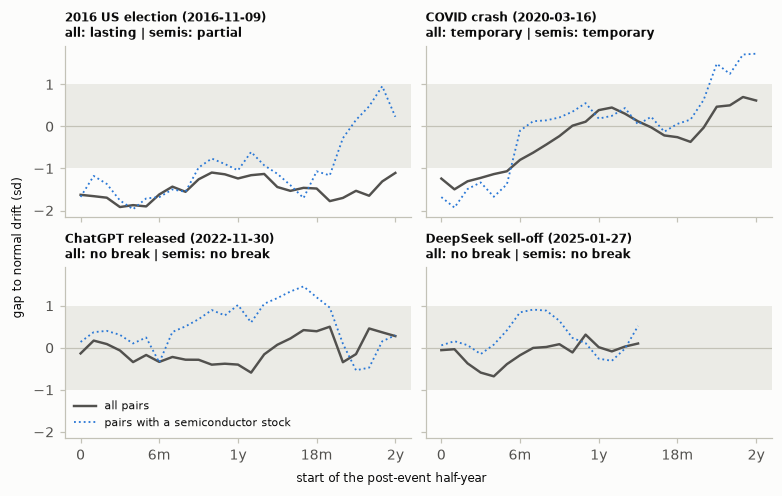

In [23]:
# Save the curves, and a compact four-event version of 6.2 for the slides.
curves.to_csv(OUT_DIR / "recovery_curves_all_pairs.csv")
curves_ai.to_csv(OUT_DIR / "recovery_curves_semi_pairs.csv")
picked = {pd.Timestamp("2016-11-09"): "2016 US election", pd.Timestamp("2020-03-16"): "COVID crash",
          pd.Timestamp("2022-11-30"): "ChatGPT released", pd.Timestamp("2025-01-27"): "DeepSeek sell-off"}
fig, axes = plt.subplots(2, 2, figsize=(7, 4.4), sharex=True, sharey=True, layout="constrained")
for ax, d in zip(axes.flat, picked):
    r = h2[h2["date"] == d.date()].iloc[0]
    ax.axhspan(-1, 1, color=GRID, alpha=0.6, lw=0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.plot(H2_OFFSETS, curves.loc[d].to_numpy(), color=INK_SOFT, lw=1.6, label="all pairs")
    ax.plot(H2_OFFSETS, curves_ai.loc[d].to_numpy(), color="#2a78d6", lw=1.2, ls=":", label="pairs with a semiconductor stock")
    ax.set_title(f"{picked[d]} ({d.date()})\nall: {r['result (all pairs)']} | semis: {r['result (pairs with a semiconductor stock)']}",
                 fontsize=8)
    ax.set_xticks([0, 126, 252, 378, 504], ["0", "6m", "1y", "18m", "2y"])
axes[1, 0].legend(frameon=False, fontsize=7, loc="lower left")
fig.supxlabel("start of the post-event half-year", fontsize=8)
fig.supylabel("gap to normal drift (sd)", fontsize=8)
save(fig, "6_3_recovery_curves_four_events")
plt.show()



## 7. Robustness: do the answers change with the settings?

The main results again under a stricter major move (z ≥ 1.5) and under raw returns (market not removed). The raw
setting is expected to look different: `comovement_rules.ipynb` showed that without removing the market, rules mostly
rediscover the market.

In [24]:
def core_results(mode, z_k):
    its, z = build_items(mode, z_k)
    an = anomaly_scores(z)
    top = np.array([POS[d] for d in an.nlargest(n_top).index])
    obs, null, p = shift_test(top, [macro_mask, shock_mask], n=300)
    br = local_break_series(its)
    ob, nb, pb, _ = shock_break_test(br, shock_days_list, n=300)
    cv, _, _ = recovery_curves(its, list(shock_rows["day"]))
    labels = [classify(z_)[0] for _, z_ in cv.iterrows()]
    return {"unusual days matched": round(obs, 2), "shifted calendars": round(null.mean(), 2), "p (unusual days)": round(p, 3),
            "shock break percentile": round(ob, 2), "shifted shocks": round(nb.mean(), 2), "p (breaks)": round(pb, 3),
            "H2 temporary": labels.count("temporary"), "H2 lasting": labels.count("lasting"),
            "H2 no break": labels.count("no break"), "H2 partial": labels.count("partial")}


robust = pd.DataFrame({
    "main: residual, z = 1.0": core_results("residual", 1.0),
    "residual, z = 1.5": core_results("residual", 1.5),
    "raw returns, z = 1.0": core_results("raw", 1.0),
}).T
robust.to_csv(OUT_DIR / "robustness.csv")
KEY["robustness"] = robust.to_dict(orient="index")
robust

,unusual days matched,shifted calendars,p (unusual days),shock break percentile,shifted shocks,p (breaks),H2 temporary,H2 lasting,H2 no break,H2 partial
"main: residual, z = 1.0",0.33,0.14,0.003,0.57,0.51,0.247,2.0,2.0,10.0,1.0
"residual, z = 1.5",0.33,0.13,0.003,0.60,0.50,0.080,3.0,3.0,9.0,0.0
"raw returns, z = 1.0",0.52,0.14,0.000,0.55,0.50,0.110,5.0,0.0,10.0,0.0


## 8. Key numbers

Every number used in the slides comes from `outputs/events/key_numbers_events.json`.

In [25]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    return o


with open(OUT_DIR / "key_numbers_events.json", "w") as f:
    json.dump(to_jsonable(KEY), f, indent=1)
print(json.dumps(to_jsonable({k: KEY[k] for k in ["q1_unusual_days", "q3_shocks_vs_breaks", "q3_recovery_all_pairs", "q3_recovery_semi_pairs"]}), indent=1))

{
 "q1_unusual_days": {
  "n_top_days": 27,
  "share_matched_macro_or_shock": 0.333,
  "null_mean": 0.138,
  "p": 0.002,
  "share_matched_macro": 0.074,
  "null_mean_macro": 0.126,
  "p_macro": 0.927,
  "share_matched_shock": 0.333,
  "null_mean_shock": 0.02,
  "p_shock": 0.0,
  "categories": {
   "one-off shock": 9,
   "scheduled release": 0,
   "earnings reaction": 6,
   "market stress": 7,
   "earnings day, reporter quiet": 1,
   "unexplained": 4
  },
  "unexplained_days": [
   "2020-11-04",
   "2017-06-09",
   "2017-12-04",
   "2017-11-29"
  ]
 },
 "q3_shocks_vs_breaks": {
  "mean_break_percentile_at_shocks": 0.566,
  "null_mean": 0.5,
  "p": 0.194,
  "n_shocks_tested": 18
 },
 "q3_recovery_all_pairs": {
  "no break": 10,
  "too recent": 3,
  "lasting": 2,
  "temporary": 2,
  "too early (no half-year before)": 1,
  "partial": 1
 },
 "q3_recovery_semi_pairs": {
  "no break": 9,
  "partial": 3,
  "too recent": 3,
  "temporary": 2,
  "too early (no half-year before)": 1,
  "lasting": 